In [35]:
#imports
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')
print("import done")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
import done


In [36]:

#loading files
folder_path = "/content/drive/My Drive/python/flipkart_order_issue_resolution_dataset"

customers_df = pd.read_csv(f"{folder_path}/customers.csv")
orders_df = pd.read_csv(f"{folder_path}/orders.csv")
sellers_df = pd.read_csv(f"{folder_path}/sellers.csv")
support_tickets_df = pd.read_csv(f"{folder_path}/support_tickets.csv")

refunds_df = pd.read_excel(f"{folder_path}/refunds.xlsx")

#JSON file
with open(f"{folder_path}/customer_complaints.json", "r") as f:
  customer_complaints = json.load(f)

#text file
with open(f"{folder_path}/status_notes.txt", "r") as f:
  status_notes = f.readlines()

print("files imported")

files imported


In [37]:
#check data
print('--- Available Data ---')
print(f'Customers: {customers_df.shape}')
print(f'Orders: {orders_df.shape}')
print(f'Sellers: {sellers_df.shape}')
print(f'Support Tickets: {support_tickets_df.shape}')
print(f'Refunds: {refunds_df.shape}')
print(f'Customer Complaints (records): {len(customer_complaints)}')
print(f'Status Notes (lines): {len(status_notes)}')

#JSON to df
complaints_df = pd.DataFrame(customer_complaints)

#text to coloumn
complaints_df['complaint_status'] = (
    complaints_df['complaint_status'].str.strip().str.title()
)
complaints_df['sentiment_tag'] = (
    complaints_df['sentiment_tag'].str.strip().str.title()
)

orders_df['order_date'] = pd.to_datetime(
    orders_df['order_date'], errors='coerce'
)
orders_df['promised_delivery_date'] = pd.to_datetime(
    orders_df['promised_delivery_date'], errors='coerce'
)
orders_df['actual_delivery_date'] = pd.to_datetime(
    orders_df['actual_delivery_date'], errors='coerce'
)

print('\nData cleaning is done')

--- Available Data ---
Customers: (1200, 6)
Orders: (5000, 14)
Sellers: (1000, 6)
Support Tickets: (1500, 8)
Refunds: (1300, 8)
Customer Complaints (records): 1500
Status Notes (lines): 100

Data cleaning is done


In [38]:


#Careate data table with all data together
master_df = (
    orders_df.merge(customers_df, on="customer_id", how="left")
    .merge(sellers_df, on="seller_id", how="left", suffixes=("", "_seller"))
    .merge(support_tickets_df, on="order_id", how="left", suffixes=("", "_support"))
    .merge(refunds_df, on="order_id", how="left", suffixes=("", "_refund"))
    .merge(
        complaints_df, on="order_id", how="left", suffixes=("", "_complaint")
    )
)

print(f"Final dataframe: {master_df.shape}")

#Display the first few rows to verify
display(master_df.head(3))

Final dataframe: (5572, 45)


,order_id,customer_id,seller_id,order_date,order_time,promised_delivery_date,actual_delivery_date,order_amount,payment_method,order_status,...,refund_completed_date,refund_reason,refund_channel,complaint_id,customer_id_complaint,complaint_date,complaint_type,complaint_description,complaint_status,sentiment_tag
0,ORD0000001,CUST000771,SELL0475,2026-05-30,10:51:46,2026-06-03,2026-06-03,57056.16,Cash on Delivery,Delivered,...,NaN,NaN,NaN,CMP000040,CUST000771,2026-05-11,Refund Delay,Customer reported refund delay for order ORD00...,Open,Negative
1,ORD0000001,CUST000771,SELL0475,2026-05-30,10:51:46,2026-06-03,2026-06-03,57056.16,Cash on Delivery,Delivered,...,NaN,NaN,NaN,CMP000555,CUST000771,2026-05-18,Wrong Item,Customer reported wrong item for order ORD0000...,Closed,Neutral
2,ORD0000002,CUST000122,SELL0035,2026-05-05,15:59:45,2026-05-08,2026-05-07,25038.34,UPI,Delivered,...,NaN,Returned Item,Wallet,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [39]:
# 1. Summary report
print("--- Summary Statistics for Numerical Features ---")
display(master_df[["order_amount", "resolution_time_hours", "refund_amount"]].describe())

# 2. Order Status Breakdown
print("\n--- Order Status Distribution ---")
order_status_counts = master_df["order_status"].value_counts()
print(order_status_counts)

# 3. Support Ticket Escalation Rate
if "escalation_flag" in master_df.columns:
  total_tickets = master_df["ticket_id"].notnull().sum()
  escalated_tickets = (master_df["escalation_flag"] == 1).sum()
  escalation_rate = (
      (escalated_tickets / total_tickets) * 100 if total_tickets > 0 else 0
  )
  print(
      f"\nSupport Ticket Escalation Rate:"
      f" {escalation_rate:.2f}% ({escalated_tickets}/{total_tickets} tickets)"
  )

# 4. Complaint Sentiment Breakdown (if available)
if "sentiment_tag" in master_df.columns:
  print("\n--- Complaint Sentiment Breakdown ---")
  print(master_df["sentiment_tag"].value_counts(dropna=False))

--- Summary Statistics for Numerical Features ---


,order_amount,resolution_time_hours,refund_amount
count,5558.000000,1439.000000,1400.000000
mean,32366.376954,92.215427,28936.752236
std,18765.212758,49.865767,20719.228653
min,-299.000000,6.000000,-65292.210000
25%,16485.117500,49.000000,12963.490000
50%,31842.765000,91.000000,25146.380000
75%,48574.380000,136.000000,44313.967500
max,64991.350000,180.000000,103024.190000



--- Order Status Distribution ---
order_status
Delivered           2993
Delayed              633
Cancelled            536
Processing           481
Returned             405
Refund Pending       286
Lost                  93
delivered             34
DELIVERED             23
 Delivered            18
delayed               11
processing             6
 Delayed               6
cancelled              6
PROCESSING             6
CANCELLED              5
DELAYED                5
 Returned              4
returned               3
 Cancelled             3
REFUND PENDING         3
 Processing            3
refund pending         2
lost                   2
RETURNED               2
 Refund Pending        1
LOST                   1
Refund_Pending         1
Name: count, dtype: int64

Support Ticket Escalation Rate: 0.00% (0/1595 tickets)

--- Complaint Sentiment Breakdown ---
sentiment_tag
NaN         4002
Negative     623
Neutral      498
Angry        369
Positive      80
Name: count, dtype: int64


In [40]:
#=====================EXECUTIVE SUMMARY & OPERATIONS MANAGER REPORT=====================================
print("===================================================================")
print("FLIPKART CUSTOMER SUPPORT OPERATIONS - BUSINESS INSIGHTS REPORT")
print("===================================================================")

# 1. Order Volume and Status Breakdown
total_orders = len(orders_df)
status_counts = orders_df["order_status"].str.strip().str.title().value_counts()
print(f"\n1. Total Customer Orders Processed: {total_orders}")
print("   Order Status Breakdown:")
for status, count in status_counts.items():
  print(f"     - {status}: {count} orders")

# 2. Cities with Highest Delayed Deliveries
print("\n2. Top Cities Experiencing Delivery Delays:")
delayed_df = orders_df[
    orders_df["order_status"].str.strip().str.title() == "Delayed"
]
top_delay_cities = delayed_df["delivery_city"].value_counts().head(5)
for city, count in top_delay_cities.items():
  print(f"     - {city}: {count} delayed deliveries")

# 3. Refund Requests Status (Pending or Failed)
refunds_clean = refunds_df.copy()
refunds_clean["refund_status"] = (
    refunds_clean["refund_status"].str.strip().str.title()
)
refund_status_counts = refunds_clean["refund_status"].value_counts()
print("\n3. Refund Requests Status Overview:")
for status, count in refund_status_counts.items():
  print(f"     - {status}: {count}")

# 4. Most Common Customer Complaint Categories
if "complaint_type" in complaints_df.columns:
  complaints_clean = complaints_df.copy()
  complaints_clean["complaint_type"] = (
      complaints_clean["complaint_type"].str.strip().str.title()
  )
  print("\n4. Most Common Customer Complaint Categories:")
  top_complaints = complaints_clean["complaint_type"].value_counts().head(5)
  for comp, count in top_complaints.items():
    print(f"     - {comp}: {count} complaints")

# 5. Orders with Repeated Complaints
complaint_counts = complaints_df["order_id"].value_counts()
repeat_orders = complaint_counts[complaint_counts > 1]
print(f"\n5. Orders with Repeated Complaints: {len(repeat_orders)} orders")

# 6. Priority Orders to Investigate First
# Defined as orders with escalated support tickets or pending/failed refunds
high_priority = master_df[
    (master_df["escalation_flag"] == 1)
    | (master_df["refund_status"].str.strip().str.title() == "Pending")
]
print(
    "\n6. High-Priority Orders Requiring Immediate Investigation:"
    f" {len(high_priority)} orders"
)
print("=" * 65)

FLIPKART CUSTOMER SUPPORT OPERATIONS - BUSINESS INSIGHTS REPORT

1. Total Customer Orders Processed: 5000
   Order Status Breakdown:
     - Delivered: 2754 orders
     - Delayed: 597 orders
     - Cancelled: 488 orders
     - Processing: 438 orders
     - Returned: 378 orders
     - Refund Pending: 258 orders
     - Lost: 86 orders
     - Refund_Pending: 1 orders

2. Top Cities Experiencing Delivery Delays:
     - Noida: 43 delayed deliveries
     - Lucknow: 41 delayed deliveries
     - Pune: 41 delayed deliveries
     - Indore: 40 delayed deliveries
     - Kolkata: 39 delayed deliveries

3. Refund Requests Status Overview:
     - Processed: 571
     - Pending: 299
     - Failed: 136
     - Initiated: 135
     - Rejected: 85
     - Not Applicable: 74

4. Most Common Customer Complaint Categories:
     - Refund Delay: 196 complaints
     - Damaged Product: 194 complaints
     - Cancellation Issue: 194 complaints
     - Wrong Item: 193 complaints
     - Late Delivery: 187 complaints

5. 

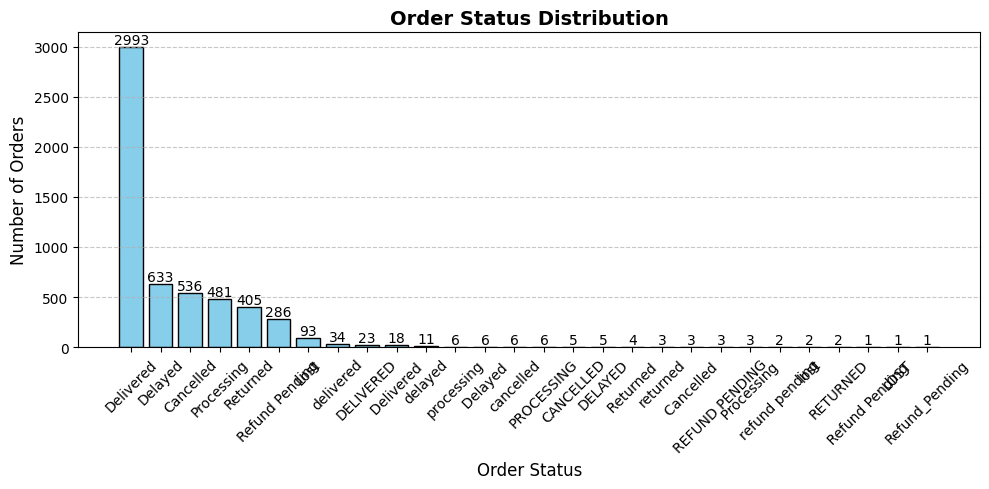

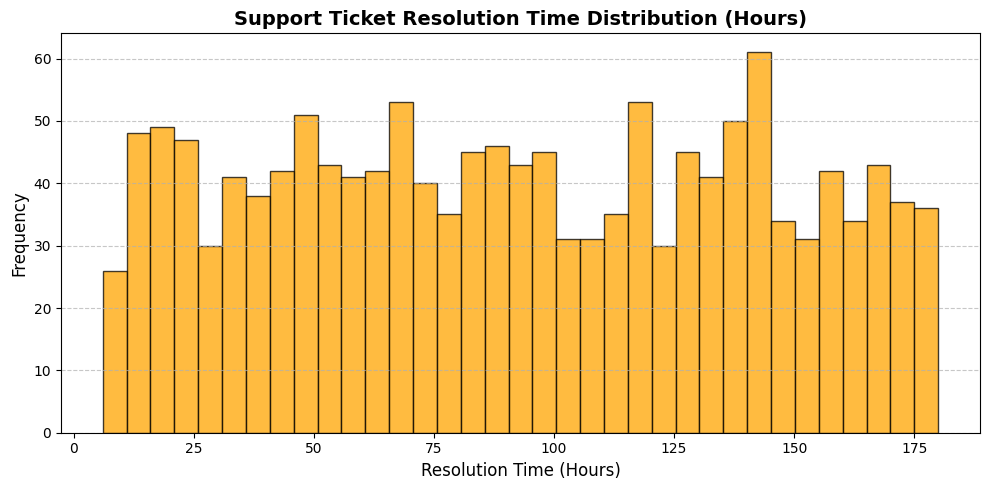

In [41]:
import matplotlib.pyplot as plt

#Order Status Distribution
status_counts = master_df["order_status"].value_counts()

plt.figure(figsize=(10, 5))
bars = plt.bar(
    status_counts.index, status_counts.values, color="skyblue", edgecolor="black"
)

plt.title("Order Status Distribution", fontsize=14, fontweight="bold")
plt.xlabel("Order Status", fontsize=12)
plt.ylabel("Number of Orders", fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.7)

#bar grapph
for bar in bars:
  height = bar.get_height()
  plt.text(
      bar.get_x() + bar.get_width() / 2.0,
      height,
      f"{int(height)}",
      ha="center",
      va="bottom",
      fontsize=10,
  )

plt.tight_layout()
plt.show()

#Resolution Time Distribution (Support Tickets)
if "resolution_time_hours" in master_df.columns:
  plt.figure(figsize=(10, 5))
  plt.hist(
      master_df["resolution_time_hours"].dropna(),
      bins=35,
      color="orange",
      edgecolor="black",
      alpha=0.75,
  )

  plt.title(
      "Support Ticket Resolution Time Distribution (Hours)",
      fontsize=14,
      fontweight="bold",
  )
  plt.xlabel("Resolution Time (Hours)", fontsize=12)
  plt.ylabel("Frequency", fontsize=12)
  plt.grid(axis="y", linestyle="--", alpha=0.7)

  plt.tight_layout()
  plt.show()
